# Nuclei and primary cilia in confocal z-stacks

A common readout in cell biology is **"how many cells, and how many of them
carry a primary cilium, and how long is it?"** It comes from a confocal
z-stack with three channels: a DNA stain (DAPI / Hoechst) for the nuclei, an
axoneme marker (acetylated tubulin, ARL13B) for the cilia, and a centrosome
marker (gamma-tubulin, pericentrin) for the basal bodies. Two image-analysis
problems hide in that readout:

1. **Nucleus instance segmentation.** Nuclei touch and, in a z-stack, can lie
   partly on top of one another. In a projection they merge into one blob,
   whose outline has at best a shallow waist, like a single elongated
   nucleus. Only the third dimension can separate them reliably.
2. **Cilium detection.** The axoneme marker also stains cytoplasmic
   microtubules, centrioles and fibre fragments. A cilium is a *specific*
   thin, straight rod with a basal body at one end. What makes it a cilium is
   a set of shape and context rules, not a brightness threshold.

`omicverse.space.seg` has one function for each problem. Neither uses a trained
model or a pixel constant:

| function | input | output |
|---|---|---|
| `ov.space.seg.segment_nuclei` | nuclear channel `(Z, Y, X)` (or `(Y, X)`) + voxel `spacing` | 2-D label image, per-nucleus table, decisions (`info`) |
| `ov.space.seg.detect_cilia` | axoneme + basal-body channels `(Z, Y, X)` + `spacing` | one row per cilium (base, tip, 3-D length, features); optionally the rejected candidates with the reason |

This tutorial simulates both kinds of field with a known ground truth. It
shows the principle behind each step, then scores the results against that
truth: counts, endpoints, orientation and lengths. It ends with the ways the
methods fail when they are misused.

## 1. Principle

### 1.1 Nuclei: distance-transform watershed, then the third dimension

**Scale from the image.** Every length is a fraction of the *typical nucleus
radius* $r$. The function estimates $r$ from a coarse Otsu mask of the
projection: it is the area-weighted median of each object's largest inscribed
radius (the maximum of the distance transform). A clump of touching nuclei
still has an inscribed radius close to that of one nucleus, so $r$ does not
depend on how crowded the field is, nor on the pixel size.

**Seeds that need a real constriction.** On the smoothed distance transform
$D(\mathbf x)$ of the foreground, a seed is an *h-maximum*: a peak that rises
at least

$$h = h_{\text{frac}}\; r$$

above the saddle that joins it to its neighbour. Two touching round nuclei
have two peaks with a deep saddle between them. An elongated nucleus with a
slight waist has a shallow saddle and keeps one seed. A fixed `min_distance` in
pixels cannot tell these two cases apart. Watershed fragments are merged back
only when their interface is wide (no neck) **and** their union is convex.

**Why a projection is not enough.** Two nuclei can overlap in $xy$ at
different heights. In the maximum projection they form one blob whose
outline has at best a shallow waist, the same waist an elongated single
nucleus has. A 2-D rule loose enough to cut the pair also cuts real nuclei.
A z-stack carries two cues that separate the two cases:

* **Focal depth** (coarse z-sampling). For each pixel, the intensity-weighted
  mean slice is
  $$f(\mathbf x) = \frac{\sum_z z\,w_z(\mathbf x)}{\sum_z w_z(\mathbf x)},\qquad w_z = \max(I_z - b_z,\,0).$$
  An object is cut in two (Otsu on $f$) when the two parts differ in mean depth
  by more than `depth_gap` times the field's typical within-nucleus depth
  spread, and when two planes fit $f$ better than one (`plane_ratio`). The
  plane test keeps a *tilted* nucleus, whose depth map is a single ramp, in one
  piece.
* **Surface steps** (fine z-sampling). When nuclei are resolved in z, every
  column has a top surface $z_t(\mathbf x)$ and a bottom surface
  $z_b(\mathbf x)$. Within one nucleus they are smooth. At the rim of a nucleus
  that lies over another one there is a near-vertical *step*, even when the two
  touch and the DAPI signal is saturated. The slope is measured in physical
  units,
  $$s(\mathbf x) = \big\lVert \nabla z_t \big\rVert\;\frac{\Delta z}{\Delta x}\quad[\mu\text{m of depth per }\mu\text{m in }xy;\ 1 = 45^\circ],$$
  hysteresis-thresholded (`step_lo`, `step_hi`). The projection mask is cut
  along those steps, and fragments are never merged across one.

**Which cue? `mode='auto'`.** The surface cue only works when one z-step is
small: a single-slice quantisation step of $z_t$ must not already look like a
rim. After the smoothing used for slopes (Gaussian scale $g$ px), the slope of
a one-slice step is about $0.4\,\Delta z/(\Delta x\, g)$. `auto` therefore uses
the surface mode only when

$$0.4\,\frac{\Delta z}{\Delta x\,g} < \texttt{step\_lo}\quad\text{and the nuclei are resolved in z (not clipped, }\ge 4\text{ slices thick)},$$

and the focal-depth mode otherwise. The ratio $\Delta z/\Delta x$ comes
from `spacing=(dz, dy, dx)`, the voxel size from the file's calibration.
**Without `spacing` there is no surface mode.**

### 1.2 Cilia: a thin straight rod with a basal body at one end

1. **Background.** Per-slice white top-hat with a disc of `bg_radius_um`
   (1 µm). Anything wider is removed, including the cytoplasmic haze and the
   cell bodies. Thin structures are kept.
2. **Field-relative intensity.** `ref` is the 99.99th percentile of the
   top-hat volume, the level of the field's brightest thin structures. Every
   intensity rule is a fraction of `ref`, so no grey-level constants are
   needed.
3. **Candidates.** 3-D hysteresis at `lo`·ref / `hi`·ref.
4. **Shape in micrometres.** Principal axes of the voxel cloud, with
   coordinates multiplied by `spacing`, give eigenvalues
   $\lambda_1\ge\lambda_2$. The length $L$ is the extent along the first
   axis, the elongation is $\sqrt{\lambda_1/\lambda_2}$ and the width is
   $4\sqrt{\lambda_2}$. The limits are physical: a cilium is 1.2–12 µm long
   and diffraction-limited in width.
5. **Basal body.** Puncta of the basal-marker top-hat (local maxima over
   1 µm, above 0.85 × that channel's own reference). One must touch an **end**
   of the object.
6. **Context rules**: what a curator rejects by eye, written as tests (Section 4).
7. **Length** along the axoneme: the 3-D path through the centroids of
   0.25-µm slabs along the main axis, from the basal body (base) to the
   free end (tip).

Lengths and distances are physical, so the same call works at another pixel
size or z-step, as long as `spacing` is correct.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, measure, morphology, segmentation, feature

import omicverse as ov
ov.plot_set(ipython_format='png')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
T0 = time.time()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 PyTorch not available - GPU detection skipped

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 2. A field of nuclei with a known answer

We build nuclei as solid shapes in micrometres. Adherent nuclei are flat
domes resting on the coverslip (a half-ellipsoid, 3.5–4.2 µm high and
10–22 µm across). We render them on a fine grid (0.15 µm in z, 0.3 µm in
$xy$), apply chromatin texture and an **anisotropic Gaussian PSF** (σ = 0.12 µm
lateral, 0.45 µm axial), and then "acquire" them twice:

* **fine stack**: every 2nd plane, Δz = 0.30 µm (Nyquist-like axial sampling);
* **coarse stack**: every 8th plane, Δz = 1.20 µm (a quick survey stack).

Each acquisition has its own Poisson shot noise, read noise, background
offset and a 12-bit ceiling. The gain is set so that most nuclear voxels are
**saturated**, as is common when DAPI is imaged next to a dim channel.

The field contains the textbook cases plus two overlapping pairs:

| nucleus | what it tests |
|---|---|
| `lone` | an isolated nucleus |
| `touchA`, `touchB` | side by side at the same height, with a constriction (2-D watershed) |
| `elong` | elongated, should not be over-split |
| `deep_low`, `deep_high` | overlap in $xy$, **3 µm apart in z** (as in a multilayer) |
| `pile_A`, `pile_B` | overlap in $xy$, B rides up on A's edge, **raised by only 1 µm** |
| `dim` | 30 % brightness, below the global Otsu level |

Ground truth in 2-D: each $xy$ column belongs to the **uppermost** nucleus
over it, the same convention the function uses for shared pixels.

In [2]:
DX, DZ_RENDER = 0.3, 0.15                 # um; render grid
H = W = 256; ZR = 96                      # 76.8 x 76.8 um field, 14.4 um deep
Z_GLASS = 1.0                             # coverslip height (um)

# name, shape, z (um: bottom of a dome / centre of an ellipsoid), (y, x) um, semi-axes (a, b, c) um, angle (deg), brightness
NUCLEI = [
    ("lone",      "dome", Z_GLASS,       (13, 13),   (7.0, 6.2, 4.0), 10, 1.0),
    ("touchA",    "dome", Z_GLASS,       (15, 40),   (6.5, 6.0, 4.0),  0, 1.0),
    ("touchB",    "dome", Z_GLASS,       (15, 52.5), (6.0, 5.5, 3.8),  0, 0.9),
    ("elong",     "dome", Z_GLASS,       (40, 66),   (11., 5.0, 3.8), 70, 1.0),
    ("deep_low",  "dome", Z_GLASS,       (42, 14),   (7.0, 6.5, 3.5),  0, 1.0),
    ("deep_high", "ell",  9.5,           (42, 23),   (6.5, 6.0, 2.0),  0, 1.0),
    ("pile_A",    "dome", Z_GLASS,       (64, 22),   (7.5, 6.5, 3.8),  0, 1.0),
    ("pile_B",    "dome", Z_GLASS + 1.0, (64, 32),   (6.5, 6.0, 3.8),  0, 1.0),
    ("dim",       "dome", Z_GLASS,       (66, 62),   (6.0, 5.6, 3.8),  0, 0.3),
]
NAMES = [n[0] for n in NUCLEI]


def render_nuclei(nuclei, seed=0):
    """Blurred DAPI signal on the render grid and the 2-D truth (uppermost nucleus per column)."""
    rng = np.random.default_rng(seed)
    zz = (np.arange(ZR) * DZ_RENDER)[:, None, None]
    yy = (np.arange(H) * DX)[None, :, None]
    xx = (np.arange(W) * DX)[None, None, :]
    obj = np.zeros((ZR, H, W), np.float32)
    own = np.zeros((ZR, H, W), np.int16)
    for i, (_, kind, z0, (cy, cx), (a, b, c), ang, bright) in enumerate(nuclei, 1):
        t = np.deg2rad(ang)
        u = (xx - cx) * np.cos(t) + (yy - cy) * np.sin(t)
        v = -(xx - cx) * np.sin(t) + (yy - cy) * np.cos(t)
        m = (u / a) ** 2 + (v / b) ** 2 + ((zz - z0) / c) ** 2 <= 1
        if kind == "dome":
            m &= zz >= z0                                    # flat bottom on the glass / support
        obj[m] = bright
        own[m] = i
    tex = ndi.gaussian_filter(rng.standard_normal(obj.shape).astype(np.float32),
                              (0.6 / DZ_RENDER, 0.6 / DX, 0.6 / DX))
    sig = obj * np.clip(1 + 0.35 * tex / tex.std(), 0.2, None)          # chromatin texture
    sig = ndi.gaussian_filter(sig, (0.45 / DZ_RENDER, 0.12 / DX, 0.12 / DX))  # anisotropic PSF
    top = np.where(own > 0, np.broadcast_to(zz, own.shape), -1.0)
    truth = np.take_along_axis(own, np.argmax(top, 0)[None], 0)[0].astype(np.int32)
    truth[(own > 0).sum(0) == 0] = 0
    return np.clip(sig, 0, None), truth, own


def acquire(sig, every, seed, gain=4500.0, offset=60.0, read=4.0, full=4095):
    """Sample every n-th render plane; Poisson shot noise + Gaussian read noise + 12-bit ceiling."""
    r = np.random.default_rng(seed)
    s = sig[::every]
    counts = r.poisson(gain * s + offset).astype(np.float32) + r.normal(0, read, s.shape)
    return np.clip(counts, 0, full).astype(np.uint16)


sig, truth, owner3d = render_nuclei(NUCLEI, seed=0)
fine = acquire(sig, 2, seed=1)
coarse = acquire(sig, 8, seed=2)
SP_FINE = (2 * DZ_RENDER, DX, DX)      # (dz, dy, dx) in um
SP_COARSE = (8 * DZ_RENDER, DX, DX)
print("fine  ", fine.shape, "spacing", SP_FINE)
print("coarse", coarse.shape, "spacing", SP_COARSE)
print("saturated fraction of nuclear pixels in the fine max projection: "
      f"{(fine.max(0)[truth > 0] >= 4095).mean():.0%}")

fine   (48, 256, 256) spacing (0.3, 0.3, 0.3)
coarse (12, 256, 256) spacing (1.2, 0.3, 0.3)
saturated fraction of nuclear pixels in the fine max projection: 59%


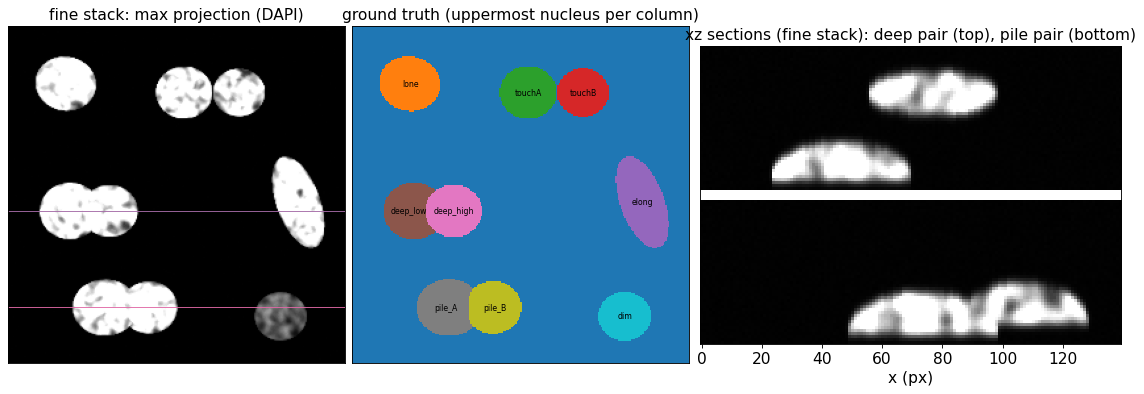

In [3]:
def outline(ax, lab, color="w", lw=0.8):
    for k in np.unique(lab)[1:]:
        ax.contour(lab == k, [0.5], colors=color, linewidths=lw)


fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True,
                         gridspec_kw=dict(width_ratios=[1, 1, 1.25]))
axes[0].imshow(fine.max(0), cmap="gray")
axes[0].set_title("fine stack: max projection (DAPI)")
axes[1].imshow(truth, cmap="tab10", interpolation="nearest")
for k, n in enumerate(NAMES, 1):
    cy, cx = ndi.center_of_mass(truth == k)
    axes[1].text(cx, cy, n, ha="center", va="center", fontsize=7, color="k")
axes[1].set_title("ground truth (uppermost nucleus per column)")
# xz section through both overlapping pairs
for row, lab_, col in ((int(42 / DX), "deep pair", "C1"), (int(64 / DX), "pile pair", "C3")):
    axes[0].axhline(row, color=col, lw=0.8)
sec = np.concatenate([fine[::-1, int(42 / DX), :140], np.full((3, 140), 4095, fine.dtype),
                      fine[::-1, int(64 / DX), :140]], 0)          # z upwards in each panel
axes[2].imshow(sec, cmap="gray", aspect=SP_FINE[0] / DX, interpolation="nearest")
axes[2].set_title("xz sections (fine stack): deep pair (top), pile pair (bottom)")
axes[2].set_xlabel("x (px)")
axes[2].set_yticks([])
for a in axes[:2]:
    a.set_xticks([]); a.set_yticks([])
plt.show()

The projection shows seven blobs, not nine. In the $xz$ sections the deep
pair is two separate layers. The pile pair is two domes pressed together, with
B's edge resting about 1 µm up on A's flank, and the saturated signal is one
continuous mass. These two pairs are the cases a 2-D method cannot solve.

## 3. `segment_nuclei`: let `mode='auto'` choose the cue

Pass the **whole stack** of the nuclear channel and its voxel size.

In [4]:
def score(truth, lab, thr=0.5):
    """Per-truth-nucleus best IoU, and counts of matched / extra labels (1:1 at IoU >= thr)."""
    best, used = {}, set()
    for t, name in enumerate(NAMES, 1):
        tm = truth == t
        vals, cnt = np.unique(lab[tm], return_counts=True)
        b, bl = 0.0, 0
        for v, c in zip(vals, cnt):
            if v == 0:
                continue
            iou = c / (tm.sum() + (lab == v).sum() - c)
            if iou > b:
                b, bl = iou, v
        best[name] = round(float(b), 2)
        if b >= thr:
            used.add(int(bl))
    n_match = sum(v >= thr for v in best.values())
    return best, n_match, int(lab.max()) - len(used)


runs = {}
for key, stack, sp in (("fine", fine, SP_FINE), ("coarse", coarse, SP_COARSE)):
    t = time.time()
    lab, table, info = ov.space.seg.segment_nuclei(stack, spacing=sp, return_info=True)
    runs[key] = (lab, table, info)
    print(f"{key:6s} -> mode={info['mode']:8s} nuclei={info['n_nuclei']}  ({time.time()-t:.1f} s)")

cues = pd.DataFrame({k: {c: runs[k][2].get(c) for c in
                         ("n_slices", "radius", "slice_step_slope", "clipped_frac",
                          "median_thickness_slices", "mode", "step_px", "n_depth_split")}
                     for k in runs}).T
cues

fine   -> mode=surface  nuclei=9  (3.9 s)
coarse -> mode=depth    nuclei=8  (0.1 s)


,n_slices,radius,slice_step_slope,clipped_frac,median_thickness_slices,mode,step_px,n_depth_split
fine,48,19.0,0.4,0.0,10.0,surface,5297,0
coarse,12,19.0,1.6,0.0,3.0,depth,None,1


**How `auto` routed the two stacks.** Both stacks are resolved in z: no nucleus
touches the first or last slice (`clipped_frac` = 0). What differs is
`slice_step_slope`, the apparent slope of a one-slice step of the surface:

* fine (Δz/Δx = 0.3/0.3): 0.40 < `step_lo` = 0.6. A single z-step is too
  small to look like a rim, so **surface mode** is used, and `step_px` pixels
  lie on surface steps.
* coarse (Δz/Δx = 1.2/0.3): 1.6 > 0.6. Each slice boundary would itself look
  like a 58° cliff, so the surface is not trustworthy and the function uses
  **focal-depth mode** (`n_depth_split` splits were made).

`radius` (≈ 19 px ≈ 5.7 µm) was estimated from the image in both runs. We
did not supply it.

In [5]:
rows = {}
for key in runs:
    best, n_match, n_extra = score(truth, runs[key][0])
    rows[f"{key} (auto -> {runs[key][2]['mode']})"] = {**best, "matched": f"{n_match}/9", "extra labels": n_extra}
forced = ov.space.seg.segment_nuclei(fine, spacing=SP_FINE, mode="depth")
best, n_match, n_extra = score(truth, forced)
rows["fine, forced mode='depth'"] = {**best, "matched": f"{n_match}/9", "extra labels": n_extra}
iou_table = pd.DataFrame(rows).T
iou_table

,lone,touchA,touchB,elong,deep_low,deep_high,pile_A,pile_B,dim,matched,extra labels
fine (auto -> surface),0.96,0.97,0.91,0.96,0.79,0.74,0.87,0.85,0.93,9/9,0
coarse (auto -> depth),0.94,0.96,0.9,0.94,0.87,0.85,0.52,0.46,0.92,8/9,0
"fine, forced mode='depth'",0.96,0.97,0.91,0.96,0.88,0.85,0.52,0.46,0.93,8/9,0


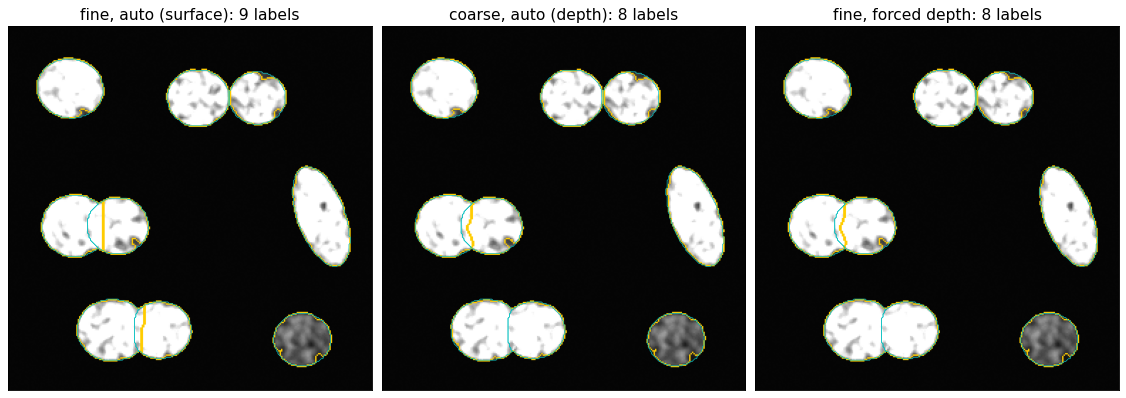

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)
for a, (title, lab) in zip(axes, [("fine, auto (surface)", runs["fine"][0]),
                                  ("coarse, auto (depth)", runs["coarse"][0]),
                                  ("fine, forced depth", forced)]):
    a.imshow(segmentation.mark_boundaries(fine.max(0) / 4095.0, lab, color=(1, 0.8, 0)))
    outline(a, truth, color="c", lw=0.6)
    a.set_title(f"{title}: {lab.max()} labels")
    a.set_xticks([]); a.set_yticks([])
plt.show()

**Reading the table** (IoU of each true nucleus with its best label;
a match is IoU ≥ 0.5, 1:1).

* **Fine stack, surface mode: 9/9, no extra labels.** The pile pair is
  separated because B's rim is a step in the nuclear volume's surface. Every
  other nucleus is a single label, including the dim one (recovered below
  the Otsu level) and the elongated one. For the deep pair the cut follows
  the step at the rim of the upper nucleus. That puts part of the overlap on
  the wrong side of the line, so its IoUs (0.79 / 0.74) are lower than with
  the depth split (0.88 / 0.85). Both are clear matches.
* **Coarse stack, depth mode.** The deep pair splits, since a 3-µm gap is a
  large difference in focal depth. The pile pair stays merged (IoU ≈ 0.5),
  because with B raised by only 1 µm and the signal saturated, the two
  nuclei's focal depths differ by less than their own internal spread. At
  Δz = 1.2 µm, a 1-µm step is not visible as a surface step either. A coarse
  stack does not contain the information, so no setting can recover it.
* **Fine stack, forced depth mode**: the same merge as the coarse stack. The
  information is in the fine stack, but the focal-depth cue cannot use it.

Cyan lines are the truth outlines and yellow lines the predicted
boundaries. The per-nucleus table returned with `return_info=True` has
area, centroid, intensity and shape for each label (and `focal_depth` in
depth mode). It can be joined to per-cell measurements:

In [7]:
runs["fine"][1].round(2)

,label,area,centroid_y,centroid_x,mean_intensity,solidity,eccentricity
0,1,1455,42.95,43.12,3913.83,0.97,0.48
1,2,1040,50.29,174.75,3682.66,0.95,0.44
2,3,1325,50.01,133.46,3781.97,0.97,0.43
3,4,1837,133.33,220.05,3902.71,0.97,0.89
4,5,1002,139.77,80.20,3729.49,0.95,0.59
5,6,1519,139.92,46.19,3944.66,0.96,0.25
6,7,1594,213.18,72.67,3816.83,0.96,0.45
7,8,1105,213.58,109.48,3928.21,0.96,0.48
8,9,1092,219.77,206.54,1544.62,0.95,0.38


### 3.1 What the surface cue looks like

To see what surface mode measures, we compute a rough top surface by hand:
the highest slice above an Otsu level in each column, in µm. Its physical
slope is in µm/µm, where 1 = 45°.

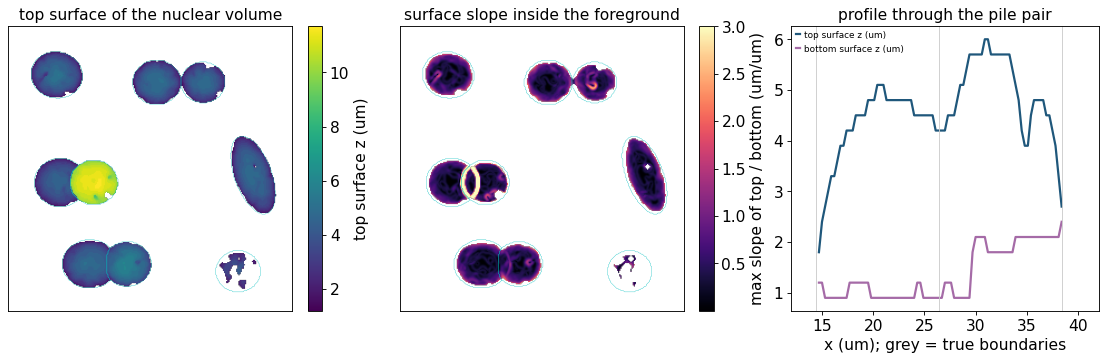

In [8]:
sm = ndi.gaussian_filter(fine.astype(np.float32), (0.5, 1.0, 1.0))
fg3 = sm > filters.threshold_otsu(sm)
has = fg3.any(0)
nz = fine.shape[0]
z_top = np.where(has, (nz - 1 - fg3[::-1].argmax(0)) * SP_FINE[0], np.nan)
z_bot = np.where(has, fg3.argmax(0) * SP_FINE[0], np.nan)


def phys_slope(z):
    zs = ndi.gaussian_filter(ndi.median_filter(np.nan_to_num(z), 3), 1.0)
    gy, gx = np.gradient(zs, DX)           # um of depth per um in xy
    return np.hypot(gy, gx)


slope = np.where(has, np.maximum(phys_slope(z_top), phys_slope(z_bot)), np.nan)
inner = ndi.binary_erosion(has, iterations=2)          # ignore the outer rim of the foreground

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
im = axes[0].imshow(z_top, cmap="viridis"); plt.colorbar(im, ax=axes[0], label="top surface z (um)")
im = axes[1].imshow(np.where(inner, slope, np.nan), cmap="magma", vmax=3)
plt.colorbar(im, ax=axes[1], label="max slope of top / bottom (um/um)")
for a in axes[:2]:
    outline(a, truth, color="c", lw=0.3); a.set_xticks([]); a.set_yticks([])
axes[0].set_title("top surface of the nuclear volume")
axes[1].set_title("surface slope inside the foreground")
row = int(64 / DX); xs = np.arange(W) * DX
axes[2].plot(xs, z_top[row], lw=2, label="top surface z (um)")
axes[2].plot(xs, z_bot[row], lw=2, label="bottom surface z (um)")
truth_edge = xs[np.nonzero(np.diff(truth[row]) != 0)[0]]
for xe in truth_edge:
    axes[2].axvline(xe, color="0.8", lw=0.8)
axes[2].set_xlim(12, 42); axes[2].set_xlabel("x (um); grey = true boundaries")
axes[2].legend(frameon=False, fontsize=8); axes[2].set_title("profile through the pile pair")
plt.show()

Within one nucleus, both surfaces are smooth: the top is a dome and the
bottom is flat on the glass. Along the profile through the pile pair, the
**bottom surface jumps by about 1 µm within one pixel** at x ≈ 29.5 µm.
This is where B, raised 1 µm, leaves A's flank. The top surface also dips
and rises again at B's rim (x ≈ 26–28 µm). In the slope map (cyan = true
outlines) the bright ring around `deep_high` is the same kind of step at the
rim of a nucleus lying over another one. The pile step is only about one
pixel wide, so it shows best in the profile. Inside single nuclei the
slopes stay below `step_hi` = 1.4, apart from texture specks. (This
hand-made map is cruder than the function's,
which smooths at scales tied to $r$, applies hysteresis and keeps only step
curves at least $r/2$ long.) In the coarse stack the same 1-µm jump is less
than one slice, so it disappears.

## 4. `detect_cilia`: a field of cilia and the things that look like them

The second field is 36 × 36 × 6 µm at Δz = 0.3 µm and Δx = Δy = 0.1 µm. To
avoid accidental contacts, it is laid out as a 4 × 4 grid of 9-µm "cells"
with one object per cell. A dense network of dim microtubules runs through
all of them, with a smooth cytoplasmic haze on top. The **axoneme channel**
(acetylated-tubulin-like) contains:

* **9 true primary cilia** (2.0–5.5 µm, tilted 5–30° out of the plane), each
  with a gamma-tubulin mother + daughter centriole pair at its base;
  * one of them continues *through* its centrosome as a dimmer fibre;
  * one has a second short bright rod starting next to the same basal body;
* distractors: 3 **curly cytoplasmic microtubule bundles**, a **straight rod
  without a basal body**, a **centriole pair** (a short rod with
  gamma-tubulin all along it), a **fibre fragment** that starts at a basal
  body but whose tip continues as a fibre after a short gap, and a **dim
  outlier** (a basal body at one end, but an axoneme much dimmer than the
  field's cilia).

The **basal-body channel** (gamma-tubulin-like) has the centrosomes plus dim
cytoplasmic speckles. We use the same imaging model: anisotropic PSF (σ 0.11 µm
lateral, 0.40 µm axial), Poisson + read noise, and a 12-bit ceiling. Rods are
drawn as a line *density*, so crossings add up and become brighter, as they
do in a real image.

In [9]:
SP_CIL = (0.3, 0.1, 0.1)                 # (dz, dy, dx) um
SHAPE_CIL = (20, 360, 360)


def unit(v):
    v = np.asarray(v, float)
    return v / np.linalg.norm(v)


def draw(vol, poly, b, um, ds=0.02):
    """Deposit a polyline (um) as a line density: b per 0.1 um of length.
    A polyline of two equal points deposits b into one voxel (a punctum)."""
    poly = np.asarray(poly, float)
    for p, q in zip(poly[:-1], poly[1:]):
        L = np.linalg.norm(q - p)
        if L == 0:
            v = np.round(p / um).astype(int)
            if np.all(v >= 0) and np.all(v < vol.shape):
                vol[tuple(v)] += b
            continue
        n = int(L / ds) + 1
        pts = p + (np.arange(n)[:, None] + 0.5) / n * (q - p)
        v = np.round(pts / um).astype(int)
        ok = np.all((v >= 0) & (v < vol.shape), 1)
        np.add.at(vol, tuple(v[ok].T), b * (L / n) / 0.1)


def curve(rng, start, length, step=0.05, turn=0.5, zdrift=0.05):
    """Persistent random walk in xy (rms heading change `turn` rad per sqrt(um)), slow z drift."""
    p, th, pts = np.array(start, float), rng.uniform(0, 2 * np.pi), []
    for _ in range(int(length / step)):
        pts.append(p.copy())
        th += rng.normal(0, turn * np.sqrt(step))
        p = p + step * np.array([rng.normal(0, zdrift), np.sin(th), np.cos(th)])
    return np.array(pts)


def cilia_field(seed=0):
    rng = np.random.default_rng(seed)
    um = np.array(SP_CIL); Z, Y, X = SHAPE_CIL; ext = np.array(SHAPE_CIL) * um
    ax = np.zeros(SHAPE_CIL, np.float32); bb = np.zeros(SHAPE_CIL, np.float32)
    rows, zc = [], 2.4
    centre = lambda i, j: np.array([zc, 4.5 + 9 * i, 4.5 + 9 * j])

    def basal_body(p):
        b = float(rng.uniform(0.92, 1.05))
        draw(bb, [p, p], b, um)                                 # mother centriole
        q = p + np.array([0, 0.35, -0.2]); draw(bb, [q, q], 0.55 * b, um)   # daughter

    def cilium(i, j, L, dxy, tilt, kind="primary cilium", shift=(0, 0)):
        d = unit([np.tan(np.deg2rad(tilt)) * np.linalg.norm(dxy), *dxy])
        B = centre(i, j) + np.array([0, *shift]) - 0.5 * L * d
        T = B + L * d
        draw(ax, [B, T], float(rng.uniform(0.92, 1.05)), um); basal_body(B)
        rows.append(dict(cell=(i, j), kind=kind, is_cilium=True, base_um=B, tip_um=T,
                         length_um=L, tilt_deg=tilt))
        return B, T, d

    def other(i, j, kind):
        rows.append(dict(cell=(i, j), kind=kind, is_cilium=False, base_um=None, tip_um=None,
                         length_um=np.nan, tilt_deg=np.nan))

    for args in [(0, 0, 3.2, (1, 0.4), 15), (0, 1, 4.5, (0.3, 1), 25), (0, 3, 2.6, (-0.6, 1), 10),
                 (2, 0, 5.5, (1, 1), 30), (2, 2, 4.0, (0.2, -1), 5), (3, 2, 3.8, (-1, 0.2), 20),
                 (3, 3, 2.0, (1, -1), 10)]:
        cilium(*args)
    # cilium whose base continues through the centrosome as a dimmer fibre
    B, T, d = cilium(1, 1, 3.6, (1, -0.05), 10, "cilium + fibre through its centrosome", shift=(1.8, 0))
    draw(ax, [B, B - 3.8 * unit([0, 1, -0.05])], 0.62, um)
    # cilium with a second short rod next to the same basal body
    B, T, d = cilium(3, 1, 4.2, (-0.3, 1), 15, "cilium + second rod on its basal body", shift=(0, 1.0))
    q = B + 0.5 * unit([0, 1, -0.3]); draw(ax, [q, q + 1.6 * unit([0, 1, -0.3])], 0.95, um)
    # curly bright cytoplasmic microtubule bundles (no basal body)
    for (i, j) in [(0, 2), (1, 3), (2, 3)]:
        while True:
            cv = curve(rng, (0, 0, 0), 8.0, turn=2.5, zdrift=0.02)
            cv = cv - cv.mean(0) + centre(i, j)
            if np.all(np.abs(cv[:, 1:] - centre(i, j)[1:]) < 4.0):
                break
        draw(ax, cv, 0.8, um); other(i, j, "curly cytoplasmic MT bundle")
    # straight bright rod, no basal body
    c, d = centre(1, 0), unit([0.1, 0.2, 1]); draw(ax, [c - 1.5 * d, c + 1.5 * d], 1.0, um)
    other(1, 0, "straight rod, no basal body")
    # centriole pair: short acetylated rod with gamma-tubulin along all of it
    c, d = centre(1, 2), unit([0, 0.3, 1]); p, q = c - 0.8 * d, c + 0.8 * d
    draw(ax, [p, q], 1.0, um)
    for s in np.linspace(0, 1, 5):
        r = p + s * (q - p); draw(bb, [r, r], 1.0, um)
    other(1, 2, "centriole pair")
    # fibre fragment: bright piece from a basal body; after a 0.5-um gap the fibre runs on
    c, d = centre(2, 1), unit([0.03, -1, -1]); B = c - 3.6 * d; T = B + 2.4 * d
    draw(ax, [B, T], 1.0, um); basal_body(B); draw(ax, [T + 0.5 * d, T + 5.0 * d], 0.7, um)
    other(2, 1, "fibre fragment (tip runs on)")
    # dim outlier: basal body at one end, axoneme at 60 % of the field's cilia
    c, d = centre(3, 0), unit([0.2, -0.3, 1]); B = c - 1.5 * d
    draw(ax, [B, B + 3.0 * d], 0.6, um); draw(ax, [B + 1.4 * d, B + 1.8 * d], 0.45, um); basal_body(B)
    other(3, 0, "dim outlier")
    # dense dim microtubule network and cytoplasmic gamma-tubulin speckles
    for _ in range(70):
        st = (rng.uniform(1.2, 4.0), rng.uniform(0, ext[1]), rng.uniform(0, ext[2]))
        draw(ax, curve(rng, st, rng.uniform(6, 20), turn=0.6), float(rng.uniform(0.1, 0.25)), um)
    for _ in range(40):
        p = np.array([rng.uniform(1, 5), rng.uniform(0, ext[1]), rng.uniform(0, ext[2])])
        draw(bb, [p, p], float(rng.uniform(0.1, 0.35)), um)
    # optics: anisotropic Gaussian PSF, normalised so a rod peaks at its brightness
    psf_a = (0.40 / um[0], 0.11 / um[1], 0.11 / um[2])
    psf_b = (0.45 / um[0], 0.18 / um[1], 0.18 / um[2])
    line = np.zeros((15, 15, 41), np.float32); line[7, 7, :] = 1
    dot = np.zeros((15, 15, 15), np.float32); dot[7, 7, 7] = 1
    a = ndi.gaussian_filter(ax, psf_a) / ndi.gaussian_filter(line, psf_a).max()
    g = ndi.gaussian_filter(bb, psf_b) / ndi.gaussian_filter(dot, psf_b).max()
    yy, xx = np.mgrid[:Y, :X] * um[1]
    haze = (0.12 * (1 + np.sin(yy / 5.0) * np.cos(xx / 7.0)))[None] * \
        np.exp(-0.5 * ((np.arange(Z) * um[0] - 2.5) / 1.5) ** 2)[:, None, None]
    return a + haze, g + 0.3 * haze, pd.DataFrame(rows)


def camera(x, seed, gain=3200.0, offset=100.0, read=5.0, full=4095):
    r = np.random.default_rng(seed)
    counts = r.poisson(np.clip(gain * x, 0, None) + offset).astype(np.float32) + r.normal(0, read, x.shape)
    return np.clip(counts, 0, full).astype(np.uint16)


ax_sig, bb_sig, objects = cilia_field(seed=0)
acet = camera(ax_sig, seed=1)                 # axoneme channel
gtub = camera(bb_sig, seed=2, gain=2500.0)    # basal-body channel
print(acet.shape, acet.dtype, "saturated voxels:", int((acet >= 4095).sum()))
objects[["cell", "kind", "is_cilium", "length_um", "tilt_deg"]]

(20, 360, 360) uint16 saturated voxels: 153


,cell,kind,is_cilium,length_um,tilt_deg
0,"(0, 0)",primary cilium,True,3.2,15.0
1,"(0, 1)",primary cilium,True,4.5,25.0
2,"(0, 3)",primary cilium,True,2.6,10.0
3,"(2, 0)",primary cilium,True,5.5,30.0
4,"(2, 2)",primary cilium,True,4.0,5.0
5,"(3, 2)",primary cilium,True,3.8,20.0
6,"(3, 3)",primary cilium,True,2.0,10.0
7,"(1, 1)",cilium + fibre through its centrosome,True,3.6,10.0
8,"(3, 1)",cilium + second rod on its basal body,True,4.2,15.0
9,"(0, 2)",curly cytoplasmic MT bundle,False,NaN,NaN


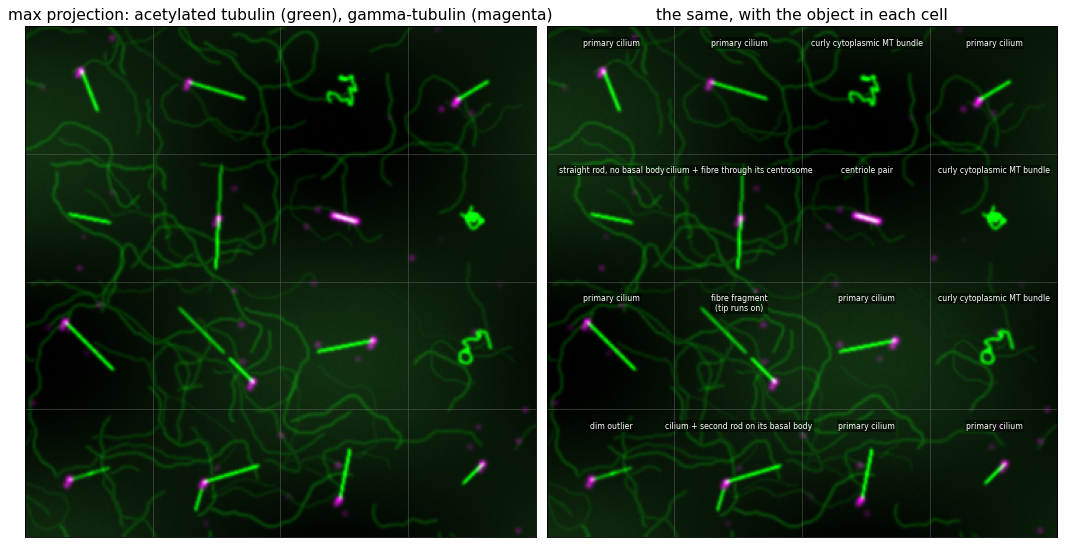

In [10]:
def show_field(ax, title):
    rgb = np.zeros(acet.shape[1:] + (3,))
    a = acet.max(0).astype(float); g = gtub.max(0).astype(float)
    rgb[..., 1] = np.clip((a - np.percentile(a, 1)) / (np.percentile(a, 99.95) - np.percentile(a, 1)), 0, 1)
    rgb[..., 0] = rgb[..., 2] = np.clip((g - np.percentile(g, 1)) / (np.percentile(g, 99.97) - np.percentile(g, 1)), 0, 1)
    ax.imshow(rgb)
    for k in range(1, 4):
        ax.axhline(90 * k - 0.5, color="0.35", lw=0.5); ax.axvline(90 * k - 0.5, color="0.35", lw=0.5)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])


fig, axes = plt.subplots(1, 2, figsize=(13, 6.6), constrained_layout=True)
show_field(axes[0], "max projection: acetylated tubulin (green), gamma-tubulin (magenta)")
show_field(axes[1], "the same, with the object in each cell")
for r in objects.itertuples():
    i, j = r.cell
    axes[1].text(90 * j + 45, 90 * i + 8, r.kind.replace(" (", "\n("), ha="center", va="top",
                 fontsize=7, color="w", bbox=dict(fc="k", alpha=0.45, lw=0, pad=1))
plt.show()

Pixel brightness alone cannot separate the cilia from the curly bundles, the
lone rod or the fragment. They are equally bright and equally thin. Only
shape and context separate them.

In [11]:
t = time.time()
cilia, rejected, cil_labels = ov.space.seg.detect_cilia(
    acet, gtub, spacing=SP_CIL, return_rejected=True, return_labels=True)
print(f"{len(cilia)} cilia accepted, {len(rejected)} candidates rejected  ({time.time()-t:.1f} s)")
print("reference levels:", {k: round(v, 1) if isinstance(v, float) else v for k, v in cilia.attrs.items()})
cilia[["cilium_id", "centroid_z", "centroid_y", "centroid_x", "base_z", "base_y", "base_x",
       "tip_z", "tip_y", "tip_x", "length_um", "elongation", "width_um", "ridge_rel",
       "basal_dist_um", "tip_continuation_um", "local_contrast"]].round(2)

9 cilia accepted, 11 candidates rejected  (3.2 s)
reference levels: {'ref': 2608.1, 'basal_ref': 1508.4, 'n_candidates': 18, 'n_basal_puncta': 12}


,cilium_id,centroid_z,centroid_y,centroid_x,base_z,base_y,base_x,tip_z,tip_y,tip_x,length_um,elongation,width_um,ridge_rel,basal_dist_um,tip_continuation_um,local_contrast
0,1,8.00,225.00,45.00,3.35,209.18,29.29,12.65,240.71,60.82,5.31,14.13,0.38,1.00,0.0,0.0,17.05
1,2,8.00,44.99,134.96,4.38,39.62,116.92,11.62,50.38,153.08,4.48,12.09,0.38,0.84,0.1,0.0,11.96
2,3,8.03,314.87,145.38,5.68,320.42,126.79,10.33,309.67,163.17,4.26,11.24,0.42,0.95,0.0,0.0,9.63
3,4,8.12,315.02,224.99,5.57,331.14,222.00,10.43,298.86,228.00,3.78,9.33,0.41,0.95,0.1,0.0,13.65
4,5,8.00,45.13,45.04,6.72,32.06,39.83,9.21,58.00,50.21,3.04,8.72,0.39,0.91,0.0,0.0,15.32
5,6,7.94,45.16,314.74,6.74,51.05,305.11,9.11,38.89,325.00,2.62,7.26,0.40,0.90,0.0,0.0,17.65
6,7,8.00,225.04,224.89,7.24,221.28,242.88,8.76,228.72,207.12,3.85,11.50,0.39,0.91,0.1,0.0,24.99
7,8,8.00,315.00,315.00,7.74,308.95,321.05,8.26,321.05,308.95,1.84,5.54,0.39,0.94,0.0,0.0,40.02
8,9,7.98,151.99,135.03,6.78,134.56,136.00,9.22,169.17,133.94,3.85,10.35,0.40,0.94,0.0,0.0,9.54


### 4.1 Score against the ground truth

Each accepted cilium is matched to the true cilium whose midpoint is nearest
in 3-D. We then compare base and tip positions in µm, check the orientation
(is the reported base nearer the true base than the true tip?) and the 3-D
length.

In [12]:
um_c = np.array(SP_CIL)
true_cilia = objects[objects.is_cilium].reset_index(drop=True)
mids = np.stack([(b + t) / 2 for b, t in zip(true_cilia.base_um, true_cilia.tip_um)])
rows = []
for r in cilia.itertuples():
    c = np.array([r.centroid_z, r.centroid_y, r.centroid_x]) * um_c
    k = int(np.argmin(np.linalg.norm(mids - c, axis=1)))
    tb, tt = true_cilia.base_um[k], true_cilia.tip_um[k]
    base = np.array([r.base_z, r.base_y, r.base_x]) * um_c
    tip = np.array([r.tip_z, r.tip_y, r.tip_x]) * um_c
    rows.append(dict(cilium_id=r.cilium_id, truth_cell=true_cilia.cell[k], kind=true_cilia.kind[k],
                     base_err_um=np.linalg.norm(base - tb), tip_err_um=np.linalg.norm(tip - tt),
                     oriented=np.linalg.norm(base - tb) < np.linalg.norm(base - tt),
                     length_true=true_cilia.length_um[k], length_found=r.length_um))
match = pd.DataFrame(rows)
match["length_err_um"] = match.length_found - match.length_true
print(f"true cilia found: {match.truth_cell.nunique()}/{len(true_cilia)}   "
      f"extra detections: {len(cilia) - match.truth_cell.nunique()}   "
      f"all oriented base->tip: {bool(match.oriented.all())}")
print(f"median |base error| {match.base_err_um.median():.2f} um, median |tip error| "
      f"{match.tip_err_um.median():.2f} um, median length error {match.length_err_um.median():+.2f} um")
match.round(2)

true cilia found: 9/9   extra detections: 0   all oriented base->tip: True
median |base error| 0.17 um, median |tip error| 0.16 um, median length error -0.02 um


,cilium_id,truth_cell,kind,base_err_um,tip_err_um,oriented,length_true,length_found,length_err_um
0,1,"(2, 0)",primary cilium,0.15,0.15,True,5.5,5.31,-0.19
1,2,"(0, 1)",primary cilium,0.20,0.20,True,4.5,4.48,-0.02
2,3,"(3, 1)",cilium + second rod on its basal body,0.20,0.21,True,4.2,4.26,0.06
3,4,"(3, 2)",primary cilium,0.17,0.17,True,3.8,3.78,-0.02
4,5,"(0, 0)",primary cilium,0.15,0.15,True,3.2,3.04,-0.16
5,6,"(0, 3)",primary cilium,0.20,0.15,True,2.6,2.62,0.02
6,7,"(2, 2)",primary cilium,0.18,0.18,True,4.0,3.85,-0.15
7,8,"(3, 3)",primary cilium,0.16,0.16,True,2.0,1.84,-0.16
8,9,"(1, 1)",cilium + fibre through its centrosome,0.09,0.16,True,3.6,3.85,0.25


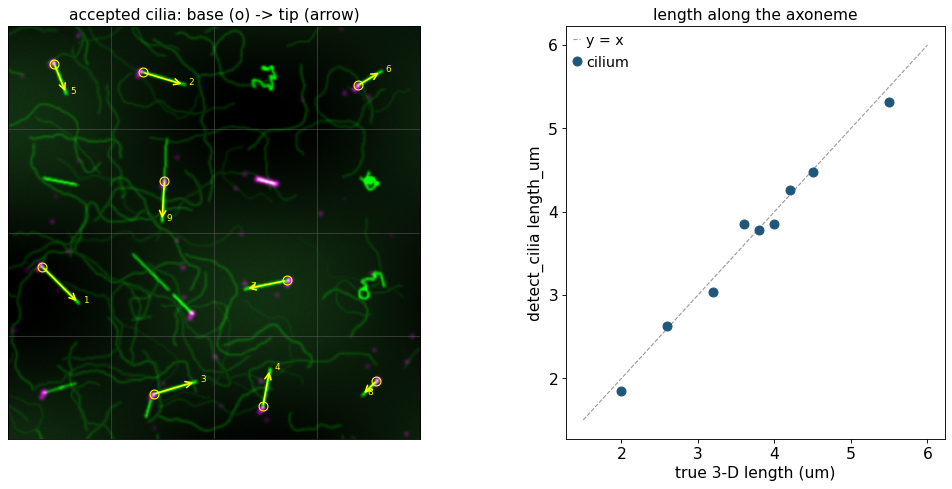

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.0), constrained_layout=True,
                         gridspec_kw=dict(width_ratios=[1.6, 1]))
show_field(axes[0], "accepted cilia: base (o) -> tip (arrow)")
for r in cilia.itertuples():
    axes[0].annotate("", xy=(r.tip_x, r.tip_y), xytext=(r.base_x, r.base_y),
                     arrowprops=dict(arrowstyle="->", color="yellow", lw=1.4))
    axes[0].plot(r.base_x, r.base_y, "o", mfc="none", mec="yellow", ms=8)
    axes[0].text(r.tip_x + 4, r.tip_y, str(r.cilium_id), color="yellow", fontsize=8)
axes[1].plot([1.5, 6], [1.5, 6], color="0.6", lw=1, ls="--", label="y = x")
axes[1].plot(match.length_true, match.length_found, "o", ms=8, label="cilium")
axes[1].set_xlabel("true 3-D length (um)"); axes[1].set_ylabel("detect_cilia length_um")
axes[1].set_title("length along the axoneme"); axes[1].legend(frameon=False)
plt.show()

**Interpretation.** All 9 true cilia are found, with no extra detection, and
every one is oriented from the basal body to the free end. Base and tip lie
within 0.1–0.2 µm of the truth, about one lateral PSF width. The lengths are
3-D lengths along the axoneme and lie within ±0.25 µm of the truth. Most
are slightly short, because the ends of a blurred rod fall below the extent
threshold. The cilium whose fibre runs on through the centrosome is slightly
long: the cut at the basal body keeps a 0.2-µm slab beyond it. The 30°-tilted 5.5-µm
cilium would be measured about 13 % too short from a 2-D projection. Here it
is measured to within a few percent.

Two of the nine needed a rule beyond "rod with a basal body at one end".
For the one with a fibre through its centrosome, the candidate was split at
its basal body and each arm was judged on its own. For the one with a
second rod, only one object per basal body is kept.

### 4.2 Why every candidate was rejected

`return_rejected=True` returns each rejected candidate with the features used
and the `reason`. We label each one with the object that was drawn in its
cell:

In [14]:
cell_of = lambda y, x: (int(y * um_c[1] // 9), int(x * um_c[2] // 9))
kind_of = {r.cell: r.kind for r in objects.itertuples()}
rejected["drawn object"] = [kind_of[cell_of(y, x)] for y, x in zip(rejected.centroid_y, rejected.centroid_x)]
rejected[["drawn object", "axis_length_um", "elongation", "width_um", "mean_rel", "peak_rel",
          "basal_frac", "tip_continuation_um", "ridge_rel", "reason"]].round(2)

,drawn object,axis_length_um,elongation,width_um,mean_rel,peak_rel,basal_frac,tip_continuation_um,ridge_rel,reason
0,curly cytoplasmic MT bundle,2.01,1.33,1.90,0.90,1.25,0.00,NaN,1.18,elongation
1,cilium + fibre through its centrosome,7.17,21.21,0.36,0.59,1.07,0.03,NaN,NaN,basal body mid-object: split into arms
2,curly cytoplasmic MT bundle,1.40,1.49,0.92,1.07,1.41,0.00,NaN,1.37,elongation
3,centriole pair,1.52,4.33,0.39,0.61,0.94,0.95,NaN,0.91,basal marker along the object (centriole pair ...
4,curly cytoplasmic MT bundle,2.93,2.18,1.60,0.63,1.23,0.00,NaN,0.88,no basal body at an end
5,fibre fragment (tip runs on),2.40,6.53,0.40,0.61,0.98,0.05,4.05,0.92,tip runs on (fragment of a longer fibre)
6,"straight rod, no basal body",2.98,8.65,0.39,0.62,0.95,0.00,NaN,0.91,no basal body at an end
7,fibre fragment (tip runs on),4.24,14.35,0.32,0.51,0.77,0.00,NaN,0.66,intensity
8,cilium + second rod on its basal body,1.58,4.66,0.37,0.58,0.85,0.00,0.00,0.84,second object on the same basal body
9,cilium + fibre through its centrosome,3.81,16.22,0.28,0.48,0.88,0.08,0.00,0.57,second object on the same basal body


In [15]:
reason_counts = rejected.groupby(["reason", "drawn object"]).size().rename("n").reset_index()
reason_counts

,reason,drawn object,n
0,basal body mid-object: split into arms,cilium + fibre through its centrosome,1
1,basal marker along the object (centriole pair ...,centriole pair,1
2,dimmer than the field's other cilia,dim outlier,1
3,elongation,curly cytoplasmic MT bundle,2
4,intensity,fibre fragment (tip runs on),1
5,no basal body at an end,curly cytoplasmic MT bundle,1
6,no basal body at an end,"straight rod, no basal body",1
7,second object on the same basal body,cilium + fibre through its centrosome,1
8,second object on the same basal body,cilium + second rod on its basal body,1
9,tip runs on (fragment of a longer fibre),fibre fragment (tip runs on),1


Each rule describes a decision a curator makes by eye:

| reason | rule | what a curator sees |
|---|---|---|
| `elongation` | $\sqrt{\lambda_1/\lambda_2}$ < 2 | **curly cytoplasmic microtubules**. A cilium is a straight rod. A curly bundle is bright and thin, but its voxel cloud is round. |
| `no basal body at an end` | no punctum within 1 µm of the proximal 45 % of either end | **a rod that is not anchored**. A primary cilium grows from the mother centriole. A bright straight rod without one is a stable microtubule bundle (also some curly pieces). |
| `basal body mid-object: split into arms` | a punctum touches the middle of the object | **a cilium plus whatever runs on through the centrosome**: a fibre, or the other centriole. The object is cut at the basal body, and each arm is judged again. |
| `basal marker along the object` | gamma-tubulin on > 35 % of the voxels | **centriole pair / centrosomal rod**. The centrioles themselves carry acetylated tubulin, but the centrosome marker covers them along their whole length. |
| `tip runs on (fragment of a longer fibre)` | signal ≥ ½ ridge continues > 1.5 µm beyond the tip | **no free distal end**. An axoneme ends at its tip. A piece of microtubule that happens to start near a centrosome continues after a short gap. |
| `second object on the same basal body` | keep the highest ridge × length per basal body | **one primary cilium per cell**. Here this caught the short rod beside a cilium, and the fibre arm left over from the mid-object split. |
| `dimmer than the field's other cilia` | ridge < 0.78 × median of the accepted cilia (with ≥ 3 cilia) | **the cilia of one field share the marker's brightness**. An object that passes every shape test but is much dimmer is a fibre fragment or out of focus. |
| `intensity` / `length` | mean / peak < 0.45 / 0.8 × ref; L outside 1.2–12 µm | dimmer pieces that still reach the hysteresis level. Here this was the fibre that continues the fragment. |

The **dim outlier** has a peak above 0.8 × ref because of its bright bead,
so the plain intensity test passes. Only the comparison with its peers
rejects it. Every rule is stated relative to physics (µm, PSF) or to the
field itself (`ref`, peer median). This is why the same defaults can be
used across stainings, objectives and exposures.

## 5. Pitfalls

### 5.1 Segmenting nuclei on a projection, or with pixel constants

A common hand-written pipeline is: max projection → Otsu → distance transform
→ `peak_local_max(min_distance=k px)` → watershed. Here it is next to
`segment_nuclei` on the projection only (`mode='2d'`).

In [16]:
proj = fine.max(0).astype(np.float32)
mask = ndi.binary_fill_holes(filters.gaussian(proj, 1, preserve_range=True) > filters.threshold_otsu(proj))
dist = ndi.distance_transform_edt(mask)
naive = {}
for md in (8, 20):
    pk = feature.peak_local_max(dist, min_distance=md, labels=measure.label(mask), exclude_border=False)
    mk = np.zeros(mask.shape, int); mk[tuple(pk.T)] = np.arange(1, len(pk) + 1)
    naive[f"naive watershed, min_distance={md} px"] = segmentation.watershed(-dist, mk, mask=mask)
naive["segment_nuclei, projection only (mode='2d')"] = ov.space.seg.segment_nuclei(proj)
naive["segment_nuclei, stack + spacing (auto)"] = runs["fine"][0]
pit = {}
for k, lab in naive.items():
    best, n_match, n_extra = score(truth, lab)
    pit[k] = {**best, "labels": int(lab.max()), "matched": f"{n_match}/9", "extra": n_extra}
pd.DataFrame(pit).T

,lone,touchA,touchB,elong,deep_low,deep_high,pile_A,pile_B,dim,labels,matched,extra
"naive watershed, min_distance=8 px",0.96,0.97,0.91,0.95,0.85,0.81,0.92,0.91,0.05,14,8/9,6
"naive watershed, min_distance=20 px",0.96,0.97,0.91,0.95,0.48,0.5,0.92,0.91,0.05,13,7/9,7
"segment_nuclei, projection only (mode='2d')",0.96,0.97,0.91,0.96,0.48,0.5,0.52,0.46,0.93,7,7/9,1
"segment_nuclei, stack + spacing (auto)",0.96,0.97,0.91,0.96,0.79,0.74,0.87,0.85,0.93,9,9/9,0


* The naive watershed produces **6–7 extra labels** at either `min_distance`.
  Chromatin texture and the saturated plateau give the distance map extra
  peaks, and every peak far enough from the others becomes a nucleus. It also
  loses the dim nucleus (IoU 0.05), because a global Otsu level on the
  projection keeps only its brightest speckles. It does cut the pile pair,
  but only because it cuts every waist, real or not. At
  `min_distance` = 20 px it already merges the deep pair. No pixel value is
  right for every nucleus, and the right value changes with the objective or
  binning. h-maxima seeding with $h \propto r$ ($r$ estimated) and the
  neck-and-convexity merge give no extra labels.
* The careful 2-D version (`mode='2d'`) merges both overlapping pairs. In a
  projection each pair is a convex blob with a wide interface, which is
  exactly what one nucleus looks like, so a rule that keeps elongated
  nuclei whole must merge the pairs. The information that separates them is
  only in the stack.

### 5.2 Forgetting `spacing`, or forcing the wrong mode

In [17]:
checks = {
    "fine, no spacing (auto)":        dict(image=fine, spacing=None, mode="auto"),
    "fine, spacing (auto)":           dict(image=fine, spacing=SP_FINE, mode="auto"),
    "coarse, forced mode='surface'":  dict(image=coarse, spacing=SP_COARSE, mode="surface"),
    "coarse, spacing (auto)":         dict(image=coarse, spacing=SP_COARSE, mode="auto"),
}
res = {}
for k, kw in checks.items():
    lab, _, info = ov.space.seg.segment_nuclei(kw.pop("image"), return_info=True, **kw)
    best, n_match, n_extra = score(truth, lab)
    res[k] = {"mode used": info["mode"], "labels": int(lab.max()), "matched": f"{n_match}/9",
              "extra": n_extra, "pile_A": best["pile_A"], "pile_B": best["pile_B"],
              "touchA": best["touchA"], "touchB": best["touchB"]}
pd.DataFrame(res).T

,mode used,labels,matched,extra,pile_A,pile_B,touchA,touchB
"fine, no spacing (auto)",depth,8,8/9,0,0.52,0.46,0.97,0.91
"fine, spacing (auto)",surface,9,9/9,0,0.87,0.85,0.97,0.91
"coarse, forced mode='surface'",surface,9,8/9,1,0.88,0.86,0.55,0.42
"coarse, spacing (auto)",depth,8,8/9,0,0.52,0.46,0.96,0.9


* **No `spacing`** → no surface mode. `auto` falls back to focal depth, and the
  pile pair is merged again, even though the fine stack contains the
  information. Always pass the calibration read from the file (ImageJ
  `spacing` / `XResolution`, OME `PhysicalSizeZ/Y/X`).
* **Forcing `mode='surface'` on a coarse stack**: each 1.2-µm slice boundary
  is a step steeper than `step_lo`, so slice boundaries become "rims".
  Here that happens to cut the pile pair. It also cuts the plain touching pair
  `touchA`/`touchB` in the wrong place (IoU 0.55 / 0.42) and adds a label,
  so no part of the result can be trusted. `auto` refuses this combination on
  purpose (`slice_step_slope` = 1.6 > `step_lo` = 0.6).

### 5.3 Cilia: a pixel-threshold pipeline

A naive pipeline thresholds the axoneme top-hat and keeps elongated objects
longer than a fixed number of pixels, with no basal-body requirement:

In [18]:
th = np.stack([s - ndi.grey_opening(s, footprint=morphology.disk(10)) for s in acet.astype(np.float32)])
mip = th.max(0)
bw = mip > filters.threshold_otsu(mip) * 1.5
props = [p for p in measure.regionprops(measure.label(bw)) if p.area >= 60 and p.eccentricity > 0.95]
kinds = pd.Series([kind_of[cell_of(*p.centroid)] for p in props]).value_counts()
print(f"naive pixel pipeline: {len(props)} 'cilia' (truth: 9)")
kinds

naive pixel pipeline: 9 'cilia' (truth: 9)


primary cilium                           5
cilium + fibre through its centrosome    1
straight rod, no basal body              1
fibre fragment (tip runs on)             1
cilium + second rod on its basal body    1
Name: count, dtype: int64

The count matches the truth, but only by accident. Two of the nine
"cilia" are the rod without a basal body and the fibre fragment. Two real
cilia are counted together with the fibre or rod that touches them, so their
lengths would be wrong. Two short real cilia are missed by the pixel
minimum. That minimum (60 px) means 0.6 µm² at this pixel size and 2.4 µm²
at twice the pixel size. Without a basal-body test and context rules, an
agreeing total says nothing about whether the objects are right.

### 5.4 Same sample, other pixel size: physical rules travel, wrong `spacing` does not

We bin the cilia field 2 × 2 in $xy$ (0.2-µm pixels, as with a lower-
magnification objective) and run `detect_cilia` twice: once with the correct
`spacing`, and once with spacing given in **pixel units** (1, 1, 1), a common
mistake when the calibration is not read from the file.

In [19]:
def bin_xy(v):
    z, y, x = v.shape
    return v.reshape(z, y // 2, 2, x // 2, 2).astype(np.float32).mean((2, 4))


acet2, gtub2 = bin_xy(acet), bin_xy(gtub)
SP_BIN = (SP_CIL[0], 2 * SP_CIL[1], 2 * SP_CIL[2])
out, lengths = {}, {}
for k, a, g, sp, f in (("original 0.1-um pixels", acet, gtub, SP_CIL, 1),
                       ("binned 0.2-um pixels, correct spacing", acet2, gtub2, SP_BIN, 2),
                       ("binned, spacing=(1, 1, 1) (pixels)", acet2, gtub2, (1.0, 1.0, 1.0), 2)):
    df = ov.space.seg.detect_cilia(a, g, spacing=sp)
    cells = [cell_of(y * f, x * f) for y, x in zip(df.centroid_y, df.centroid_x)]
    hit = sum(c in cells for c in true_cilia.cell)
    extras = [kind_of[c] for c in cells if c not in set(true_cilia.cell)]
    out[k] = {"accepted": len(df), "true cilia found": f"{hit}/9", "extras": "; ".join(extras) or "-"}
    lengths[k] = dict(zip(cells, df.length_um.round(2)))
display(pd.DataFrame(out).T)
lt = pd.DataFrame({k: v for k, v in lengths.items() if v}).reindex(list(true_cilia.cell))
lt.insert(0, "true length", true_cilia.length_um.values)
lt

,accepted,true cilia found,extras
original 0.1-um pixels,9,9/9,-
"binned 0.2-um pixels, correct spacing",11,9/9,fibre fragment (tip runs on); dim outlier
"binned, spacing=(1, 1, 1) (pixels)",0,0/9,-


true length  original 0.1-um pixels  binned 0.2-um pixels, correct spacing
0 0          3.2                    3.04                                   2.69
  1          4.5                    4.48                                   4.20
  3          2.6                    2.62                                   2.34
2 0          5.5                    5.31                                   5.05
  2          4.0                    3.85                                   3.71
3 2          3.8                    3.78                                   3.44
  3          2.0                    1.84                                   1.42
1 1          3.6                    3.85                                   3.58
3 1          4.2                    4.26                                   4.03

* **Correct `spacing`**: the same 9 true cilia are found with the same
  defaults at half the resolution. Their lengths are 0.15–0.4 µm shorter,
  because a coarser pixel clips more of each blurred end. Two borderline
  distractors now pass. The fragment's tip loses about 0.4 µm, so the
  0.5-µm gap to the fibre that continues it looks like a free end. The dim
  outlier's peer ratio lands just above the 0.78 cut. Physical rules carry
  the method across pixel sizes to first order, but the margins of the
  context rules are moderate. When the sampling changes, check the rejected
  table and an overlay again.
* **Spacing in pixel units**: every physical rule is now off by a factor
  of 5–10. The 1-µm top-hat becomes 1 px, the 1.2–12-µm length window
  becomes 1.2–12 px, and the 1-µm basal-body contact distance becomes 1 px.
  Nothing is accepted, and any "length" would be in pixels. `spacing` is part
  of the measurement.

## 6. Summary

* `segment_nuclei(stack, spacing=(dz, dy, dx))` estimates the nucleus scale
  from the image, seeds a distance-transform watershed with h-maxima, merges
  only fragments that have no neck and a convex union, and uses the third
  dimension in one of two ways. `mode='auto'` uses **surface steps** when
  the nuclei are resolved in z and one z-step is fine relative to the pixel
  size, and **focal depth** otherwise. Nuclei piled with almost no z gap need
  a fine stack *and* `spacing`.
* `detect_cilia(axoneme, basal, spacing)` accepts a thin, straight rod with a
  basal body at one end and a free tip, salient and as bright as its peers.
  It returns base, tip and 3-D length, and with `return_rejected=True` it
  gives the reason for every rejected candidate. Check those reasons on an
  overlay before trusting a count from a new staining.

## References

* Otsu N. A threshold selection method from gray-level histograms.
  *IEEE Trans. Syst. Man Cybern.* 9, 62–66 (1979).
* Vincent L, Soille P. Watersheds in digital spaces: an efficient algorithm
  based on immersion simulations. *IEEE Trans. Pattern Anal. Mach. Intell.*
  13, 583–598 (1991).
* Soille P. *Morphological Image Analysis: Principles and Applications*,
  2nd ed. Springer (2003): h-maxima, top-hat.
* Malpica N et al. Applying watershed algorithms to the segmentation of
  clustered nuclei. *Cytometry* 28, 289–297 (1997).
* Lin G et al. A hybrid 3D watershed algorithm incorporating gradient cues and
  object models for automatic segmentation of nuclei in confocal image stacks.
  *Cytometry A* 56, 23–36 (2003).
* Canny J. A computational approach to edge detection. *IEEE Trans. Pattern
  Anal. Mach. Intell.* 8, 679–698 (1986): hysteresis thresholding.
* Pawley JB (ed.). *Handbook of Biological Confocal Microscopy*, 3rd ed.
  Springer (2006): axial PSF and z-sampling.
* Piperno G, Fuller MT. Monoclonal antibodies specific for an acetylated form
  of alpha-tubulin recognize the antigen in cilia and flagella from a variety
  of organisms. *J. Cell Biol.* 101, 2085–2094 (1985).
* Satir P, Christensen ST. Overview of structure and function of mammalian
  cilia. *Annu. Rev. Physiol.* 69, 377–400 (2007).
* Hansen JN et al. CiliaQ: a simple, open-source software for automated
  quantification of ciliary morphology and fluorescence in 2D, 3D, and 4D
  images. *Eur. Phys. J. E* 44, 18 (2021).

In [20]:
print(f"total runtime {time.time() - T0:.0f} s")

total runtime 19 s
